In [1]:
import numpy as np
from dmipy.signal_models.gaussian_models import G1Ball
from microtool.dmipy import DmipyMultiTissueModel

# Setup up a simple model in dmipy, where lambda_iso represents the diffusivity.
simple_ball_dmipy = G1Ball(lambda_iso=2e-9)

# Convert it to a MICROtool compatible model.
simple_ball_microtool = DmipyMultiTissueModel(simple_ball_dmipy)
print(simple_ball_microtool)

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool_2/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tissue model with 2 scalar parameters:
Tissue-parameter       Value    Scale  Optimize    Fit    Fit Bounds
-------------------  -------  -------  ----------  -----  ------------------------------------------------
G1Ball_1_lambda_iso    2e-09    1e-09  True        True   (1.0000000000000002e-10, 3.0000000000000004e-09)
S0                     1        1      False       False  (0.0, inf)


In [2]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 2
block_size = n_directions + 1  # b0 + n_directions

shell_bvals = [1500, 2500]
shell_deltas = [0.0258, 0.0205]
shell_Deltas = [0.0434, 0.0331]
initial_te = 0.09

# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# TE and timing: one free value for each 7-measurement shell block.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Gradient magnitude: fix b0, then share one value across each shell's six DW measurements.
b0_mask = b_vals == 0
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

print("TE free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Timing free indices:",
      np.flatnonzero(initial_scheme["DiffusionPulseDuration"].optimize_mask))
print("Gradient free indices:",
      np.flatnonzero(magnitude.optimize_mask))

print(initial_scheme)


TE free indices: [0 7]
Timing free indices: [0 7]
Gradient free indices: [1 8]
Acquisition scheme with 14 measurements and 6 scalar parameters. 
total number of optimized parameters is 8:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.065)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                       -0                                          2.45176                                       1.5708                                          0.0258                                        0.0434                            0.09
                          

In [3]:
signal = simple_ball_microtool(initial_scheme )
print(signal)

jac = simple_ball_microtool.scaled_jacobian(initial_scheme)
print(jac)

[1.         0.04978707 0.04978707 0.04978707 0.04978707 0.04978707
 0.04978707 1.         0.00673795 0.00673795 0.00673795 0.00673795
 0.00673795 0.00673795]
[[ 0.        ]
 [-0.07468061]
 [-0.07468061]
 [-0.07468061]
 [-0.07468061]
 [-0.07468061]
 [-0.07468061]
 [ 0.        ]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]]


In [4]:
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme

import numpy as np
from microtool.optimize.loss_functions import compute_loss, gauss_loss


method = methods.SOMA()
optimal_scheme, _ = optimize_scheme(
    initial_scheme, simple_ball_microtool, noise_variance=0.02, method=method
)

Manually setted max fevals to: 60000
[SOMA] Starting Optimization
  Dimension (Nx)     : 8
  Population Size    : 50
  Max Migrations     : 100
  Max Fevals         : 60000
  Jumps per movement : 28
[SOMA Init] Initial Best Cost: inf | Initial Fevals: 50
----------------------------------------------------------------------
[SOMA] Mig 000/100 | Fevals: 001422/060000 | Best Cost: 9.670420e-01 | Delta: +inf | 
[SOMA] Mig 001/100 | Fevals: 002794/060000 | Best Cost: 8.532684e-02 | Delta: +8.817e-01 | 


/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool_2/lib/python3.8/site-packages/dmipy/utils/utils.py:333: RuntimeWarning: invalid value encountered in divide
  theta = np.arccos(z / r)


[SOMA] Mig 002/100 | Fevals: 004166/060000 | Best Cost: 8.532684e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 003/100 | Fevals: 005538/060000 | Best Cost: 6.194102e-02 | Delta: +2.339e-02 | 
[SOMA] Mig 004/100 | Fevals: 006910/060000 | Best Cost: 6.092346e-02 | Delta: +1.018e-03 | 
[SOMA] Mig 005/100 | Fevals: 008282/060000 | Best Cost: 5.078038e-02 | Delta: +1.014e-02 | 
[SOMA] Mig 006/100 | Fevals: 009654/060000 | Best Cost: 4.939850e-02 | Delta: +1.382e-03 | 
[SOMA] Mig 007/100 | Fevals: 011026/060000 | Best Cost: 4.939850e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 008/100 | Fevals: 012398/060000 | Best Cost: 4.928010e-02 | Delta: +1.184e-04 | 
[SOMA] Mig 009/100 | Fevals: 013770/060000 | Best Cost: 4.928010e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 010/100 | Fevals: 015142/060000 | Best Cost: 4.928010e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 011/100 | Fevals: 016514/060000 | Best Cost: 4.928010e-02 | Delta: +0.000e+00 | 
[SOMA] Mig 012/100 | Fevals: 017886/060000 | Best Cost: 4.926094e-02 | Delta: +1

In [5]:
print(optimal_scheme)
print(optimal_scheme.b_values)


Acquisition scheme with 14 measurements and 6 scalar parameters. 
total number of optimized parameters is 8:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.065)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                       -0                                          2.45176                                       1.5708                                       0.0108259                                     0.0502999                       0.0802485
                                        0.0357231                                 -2.57288               

In [10]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats

# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

simulation = MonteCarloSimulation(
    initial_scheme,
    simple_ball_microtool,
    noise_distribution,
    n_sim=100
)
simulation.run()
dmipy_initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme)
simulation.run()
dmipy_optimal = simulation.result


Starting Monte Carlo with 100 simulations: 100%|██████████| 100/100 [00:11<00:00,  8.34it/s]


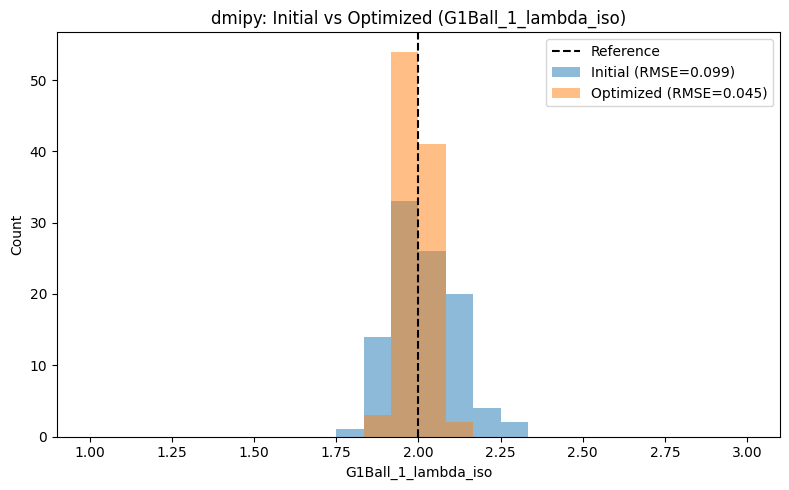

In [15]:
import numpy as np
from matplotlib import pyplot as plt

param_name = "G1Ball_1_lambda_iso"

# Extract the float value from the TissueParameter
reference = (float(simple_ball_microtool[param_name].value))*1e9

# Extract fitted values from your result containers
dmipy_initial_values = (np.asarray(dmipy_initial[param_name], dtype=float).ravel())*1e9
dmipy_optimal_values = (np.asarray(dmipy_optimal[param_name], dtype=float).ravel())*1e9

# Calculate RMSE
dmipy_initial_rmse = np.sqrt(np.mean((dmipy_initial_values - reference) ** 2))
dmipy_optimal_rmse = np.sqrt(np.mean((dmipy_optimal_values - reference) ** 2))

# Common histogram bins around the reference
bins = np.linspace(0.5 * reference, 1.5 * reference, 25)

# --------------------------------------------------
# Plot: dmipy
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.axvline(
    reference,
    color="black",
    linestyle="--",
    label="Reference"
)

plt.hist(
    dmipy_initial_values,
    bins=bins,
    alpha=0.5,
    label=f"Initial (RMSE={dmipy_initial_rmse:.3f})"
)

plt.hist(
    dmipy_optimal_values,
    bins=bins,
    alpha=0.5,
    label=f"Optimized (RMSE={dmipy_optimal_rmse:.3f})"
)

plt.xlabel(f"{param_name}")
plt.ylabel("Count")
plt.title(f"dmipy: Initial vs Optimized ({param_name})")
plt.legend()
plt.tight_layout()
plt.show()